# 15-FreeRTOS消息队列与任务间数据通信


## 1. 本篇内容与学习目标

本篇对应 `20消息队列.pptx`，围绕 FreeRTOS 消息队列展开。消息队列把“任务同步”和“数据传递”结合起来：发送任务把固定大小的数据副本放入队列，接收任务按先进先出顺序取出并处理。

学习重点包括消息队列的工作原理、与栈和信号量的区别、创建/发送/接收 API，以及 `int`、字符串和结构体等数据类型的使用方式。主课件共14页，第14页为品牌结束页，教学内容覆盖第1—13页。

下面的 C 代码用于解释 API 和任务之间的数据流，没有把课件中的板级工程、任务参数或运行结果扩展为已验证事实。


## 2. 为什么需要消息队列

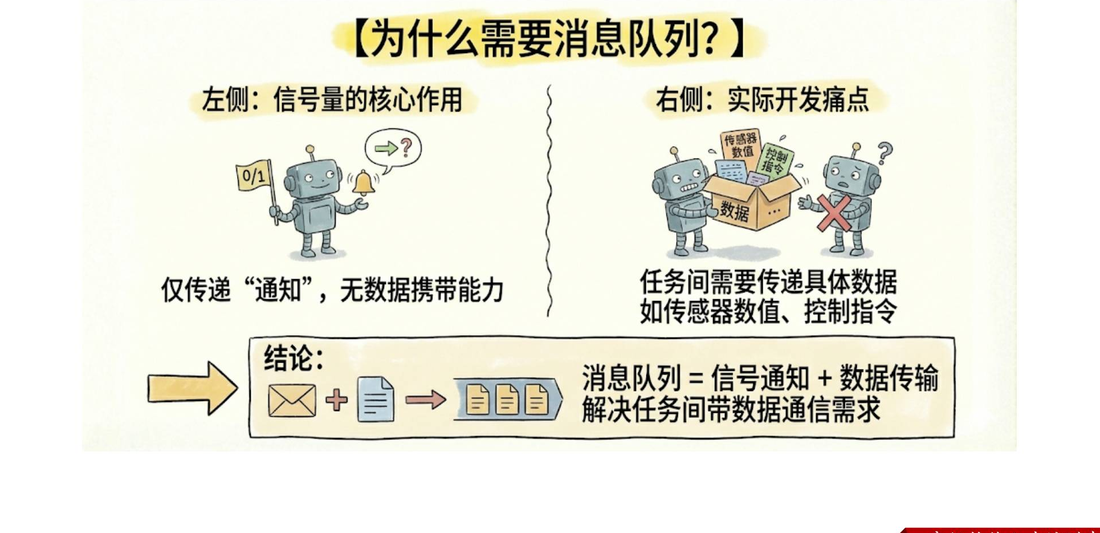

信号量适合表达“某个事件发生了”或“某个资源可用”，但它本身不携带业务数据。例如，按键中断可以用二值信号量唤醒任务，却无法直接告诉任务“这次按键对应 500 ms 还是 2000 ms”。

消息队列在通知之外保存消息内容，适合传递传感器采样值、控制指令、按键参数和任务结果。发送方和接收方通过队列解耦：发送方只负责提交数据，接收方按自己的节奏处理数据。

可以把它理解为：

```text
发送任务  ->  [消息1][消息2][消息3]  ->  接收任务
                  FIFO 先进先出
```

队列元素是数据的副本。发送任务修改自己的变量，不会改变已经复制进队列的那一份数据。

准确地说，内核按创建时的元素字节数复制数据，不会检查 C 类型。应用必须约定统一的消息格式。以下 FIFO 顺序指使用 `xQueueSend()` 向队尾发送的常规情况。


## 3. 消息队列的核心概念

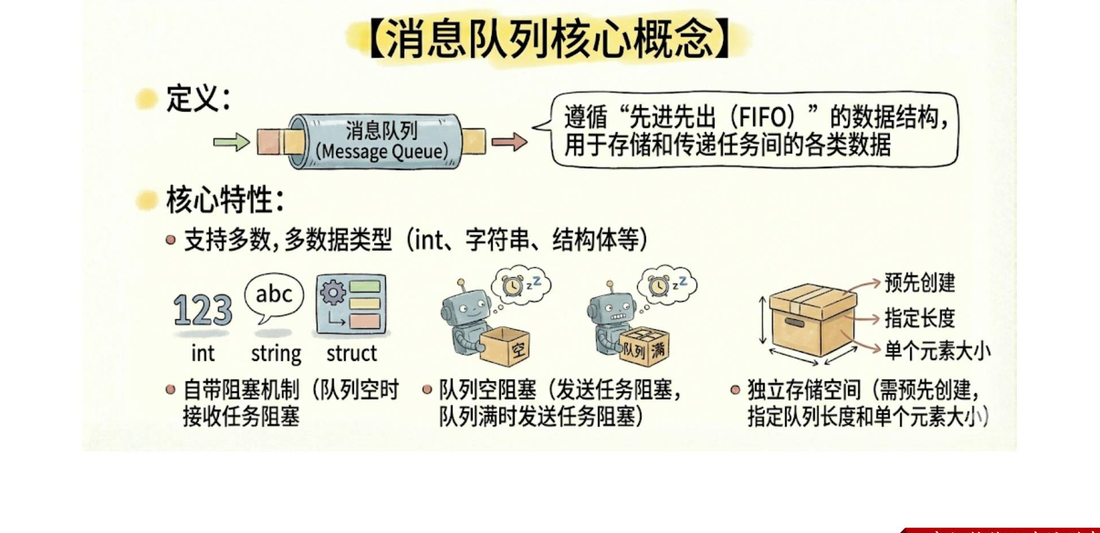

消息队列是一种预先分配存储空间的数据结构，核心规则如下：

- **FIFO**：先发送的消息先被接收，适合保持任务数据的处理顺序。
- **固定元素大小**：创建时指定队列最多保存多少个元素，以及每个元素占多少字节。
- **多种数据类型**：可以保存 `int`、字符数组或结构体，只要发送、接收两端使用相同的元素大小和布局。
- **阻塞机制**：队列为空时，接收任务可以等待；队列已满时，发送任务可以等待，避免忙等轮询。
- **独立存储空间**：队列创建后拥有自己的存储区，不能把任意大小的数据直接塞入同一个队列。

消息队列长度要结合生产速度和消费速度规划。长度过小会频繁出现队列满，长度过大则会增加 RAM 占用和消息滞留时间。

课件概念图对空/满阻塞的部分文字存在混写，应按以下规则理解：**队列空，接收方等待数据；队列满，发送方等待空间**。是否进入阻塞还取决于等待时间参数。


## 4. 消息队列、栈与信号量的区别

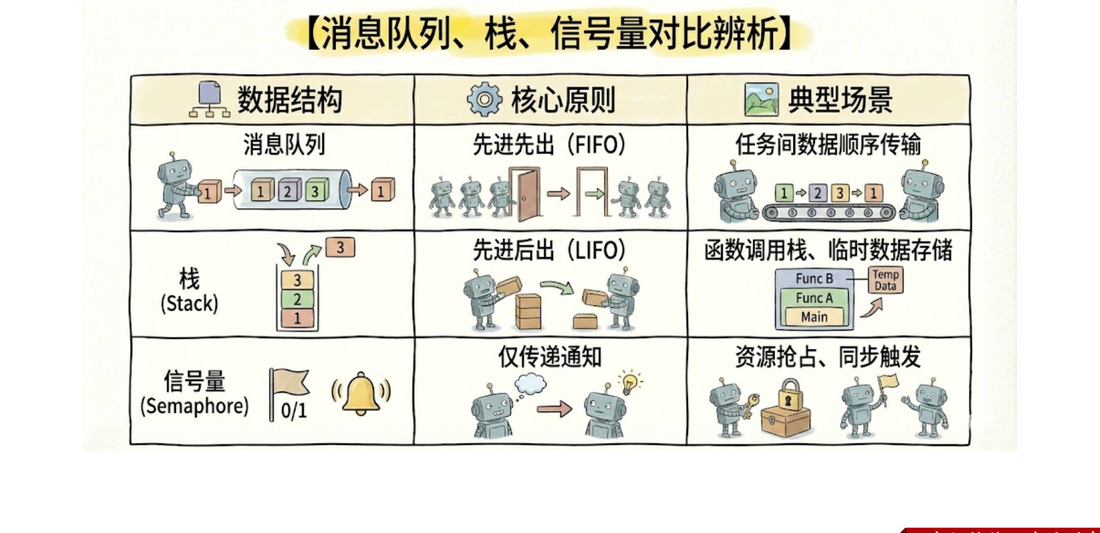

| 对象 | 数据组织 | 核心规则 | 典型用途 |
|---|---|---|---|
| 消息队列 | 多个固定大小元素 | FIFO，元素携带数据 | 任务间顺序传输命令或采样值 |
| 栈 | 一组临时数据 | LIFO，后进先出 | 函数调用现场、局部变量和临时数据 |
| 信号量 | 计数或二值状态 | 表示事件或资源数量 | 任务同步、资源计数和事件通知 |

选择时先看通信内容：只需要表达“发生了”时，信号量通常足够；需要把数值、状态或结构体一起传给另一个任务时，消息队列更合适；需要在函数调用中保存临时数据时，使用栈。

消息队列仍然可以配合信号量使用，例如用信号量通知数据到达，再让任务从队列中读取，但大多数场景下 `xQueueReceive()` 自带的阻塞机制已经足够。


## 5. 创建消息队列

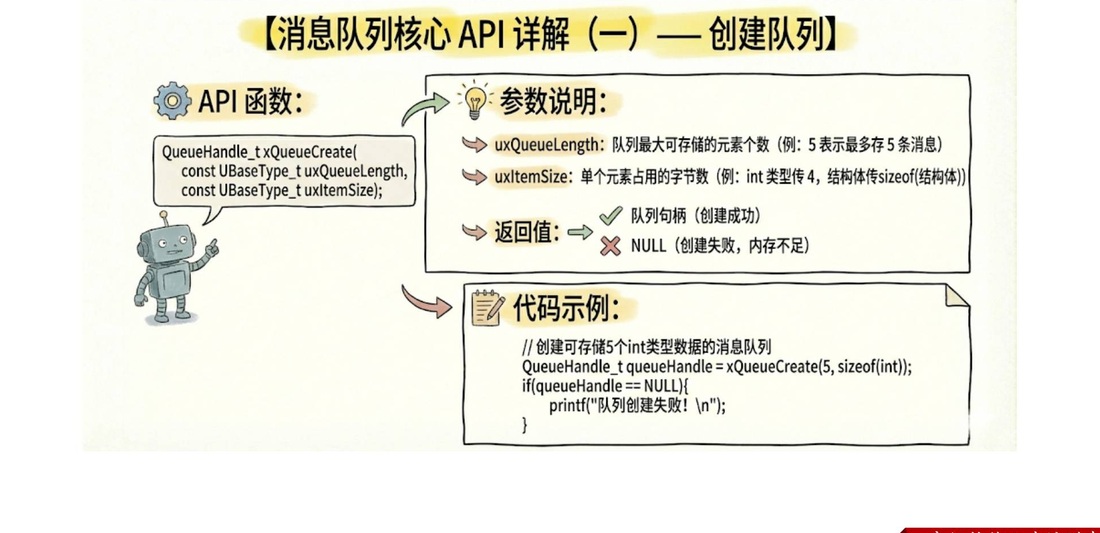

`xQueueCreate()` 的原型是：

```c
QueueHandle_t xQueueCreate(
    UBaseType_t uxQueueLength,
    UBaseType_t uxItemSize
);
```

参数含义：

- `uxQueueLength`：队列最多保存的元素数量，例如 `5` 表示最多存放5条消息。
- `uxItemSize`：单个元素的字节数。`int` 可以写 `sizeof(int)`，结构体应写 `sizeof(结构体类型)`。

返回值是 `QueueHandle_t`。创建成功得到队列句柄，失败返回 `NULL`，常见原因是堆空间不足。创建后必须检查句柄：

```c
QueueHandle_t queueHandle = xQueueCreate(5, sizeof(int));
if (queueHandle == NULL) {
    handle_queue_create_error();
}
```

队列句柄需要保存到发送任务和接收任务都能访问的位置。若采用静态队列创建，则还要由应用提供队列控制块和存储缓冲区。


## 6. 发送消息

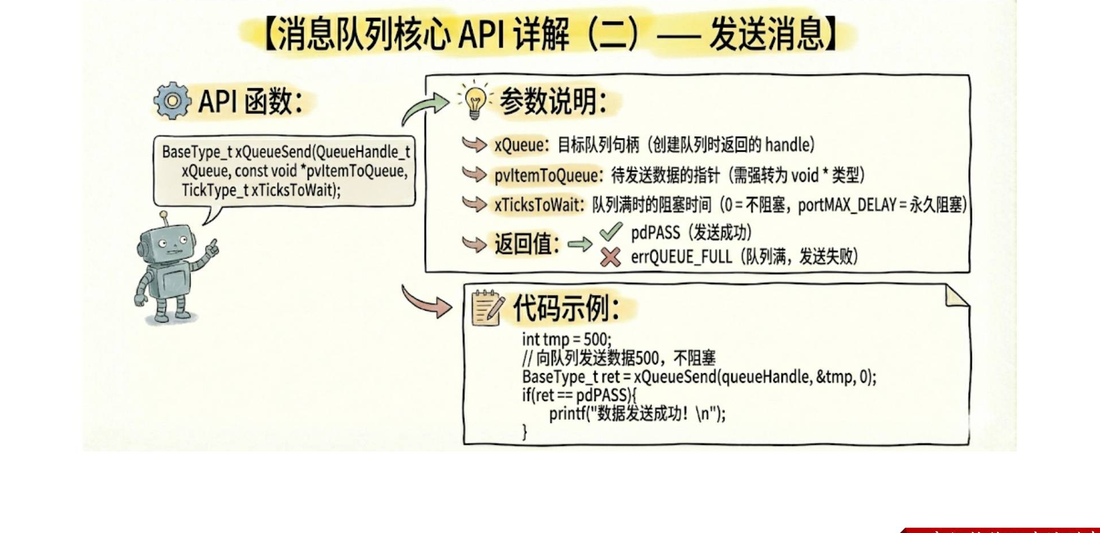

`xQueueSend()` 将发送缓冲区中的一个元素复制到队列：

```c
BaseType_t xQueueSend(
    QueueHandle_t xQueue,
    const void *pvItemToQueue,
    TickType_t xTicksToWait
);
```

示例：

```c
int command = 500;
BaseType_t ret = xQueueSend(queueHandle, &command, 0);
if (ret == pdPASS) {
    log_message_sent();
}
```

`pvItemToQueue` 必须指向一个大小至少为 `uxItemSize` 的对象。函数会复制对象内容，因此局部变量在函数返回后仍然不会影响队列中的消息。

第三个参数控制队列满时的等待时间：`0` 表示立即返回，其他值以系统节拍（tick）为单位，毫秒需用 `pdMS_TO_TICKS()` 转换。`portMAX_DELAY` 在 `INCLUDE_vTaskSuspend` 为1时可表示无限等待，否则是一个很长的有限等待值。队列已满且超时后，函数返回 `errQUEUE_FULL`。

`xQueueSend()` 向队尾写入消息。函数成功返回后，数据已经完成复制，发送方可复用原变量；调用期间源缓冲区必须保持有效，并避免其他执行上下文同时修改它。成功发送只代表消息进入队列，尚不代表接收任务已完成处理。

任务上下文中使用 `xQueueSend()`；如果发送动作发生在中断服务函数中，应使用 `xQueueSendFromISR()`，并根据需要请求一次任务切换。


## 7. 接收消息

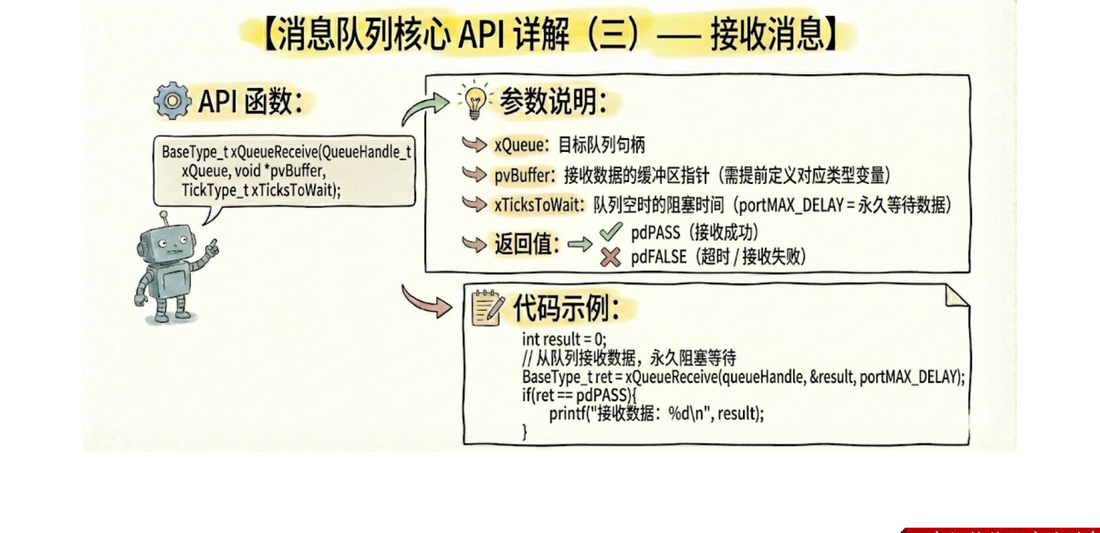

`xQueueReceive()` 从队列头部取出一个元素，并复制到接收缓冲区：

```c
BaseType_t xQueueReceive(
    QueueHandle_t xQueue,
    void *pvBuffer,
    TickType_t xTicksToWait
);
```

典型接收任务：

```c
int command = 0;
for (;;) {
    if (xQueueReceive(queueHandle, &command, portMAX_DELAY) == pdPASS) {
        process_command(command);
    }
}
```

`pvBuffer` 指向的空间必须能容纳一个完整队列元素。队列为空时，任务可以等待新消息；等待超时后返回 `pdFALSE`。接收成功返回 `pdPASS`，并且队列中的这条消息被移除。

中断服务函数中使用 `xQueueReceiveFromISR()`。不要在 ISR 中使用可能长时间阻塞的普通接收 API。


## 8. 实战案例一：`int` 类型消息队列

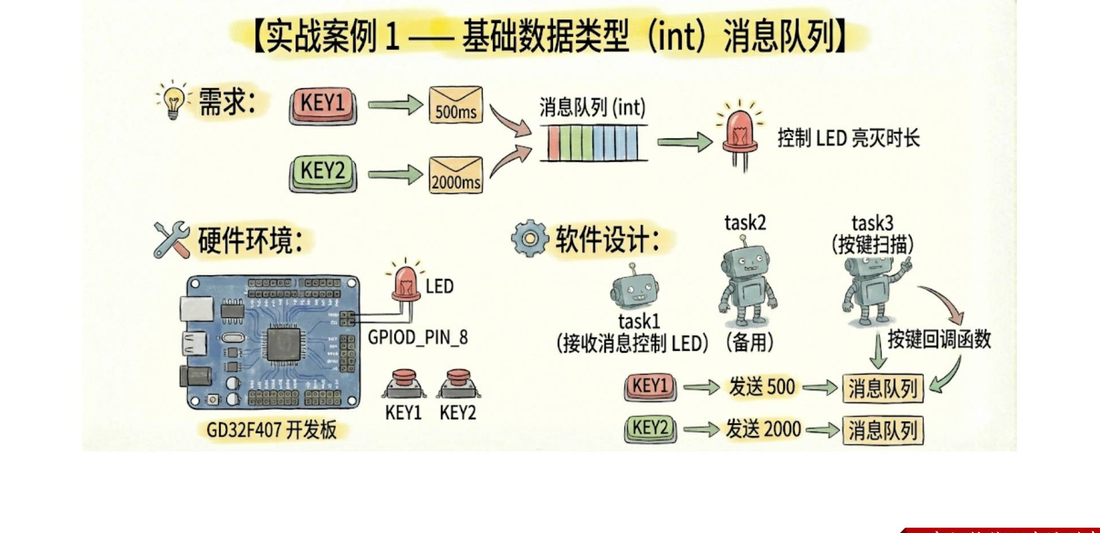

课件案例用两个按键产生不同的延时参数，接收任务根据消息控制 LED 亮灯时长：按键1发送 `500`，按键2发送 `2000`。

一种清晰的任务分工是：

```c
QueueHandle_t commandQueue;

BaseType_t create_command_queue(void)
{
    commandQueue = xQueueCreate(5, sizeof(int));
    return commandQueue != NULL ? pdPASS : pdFAIL;
}

void key_task(void *argument)
{
    for (;;) {
        if (key1_pressed()) {
            int ms = 500;
            if (xQueueSend(commandQueue, &ms, 0) != pdPASS) {
                record_dropped_command();
            }
        }
        if (key2_pressed()) {
            int ms = 2000;
            if (xQueueSend(commandQueue, &ms, 0) != pdPASS) {
                record_dropped_command();
            }
        }
        vTaskDelay(pdMS_TO_TICKS(10));
    }
}

void led_task(void *argument)
{
    int duration_ms;
    for (;;) {
        if (xQueueReceive(commandQueue, &duration_ms, portMAX_DELAY) == pdPASS) {
            led_on();
            vTaskDelay(pdMS_TO_TICKS(duration_ms));
            led_off();
        }
    }
}
```

先成功创建队列，再启动发送和接收任务；创建失败时停止启动依赖它的任务。示例需包含 `FreeRTOS.h`、`task.h`、`queue.h`，按键和 LED 函数由板级代码实现。`key1_pressed()`、`key2_pressed()` 约定返回消抖后的单次按下事件，避免长按每10 ms重复入队。课件还列出了备用 task2，本案例的数据通路只涉及按键扫描与 LED 接收任务。

课件硬件示意为 GD32F407 开发板、两个按键和位于 `GPIOD_PIN_8` 的 LED，实际引脚与有效电平应以项目原理图和驱动为准。如果按键回调由扫描任务调用，可用普通发送 API；如果回调在 ISR 中执行，就应改用 FromISR 版本。

当 LED 任务等待2000 ms时，新命令仍可以进入队列，LED 任务完成当前动作后依次处理。队列满时示例记录丢弃，不会自动覆盖旧消息。若要求新命令立即打断当前亮灯，应另外设计可中断的控制流程。

代码展示的是任务间通信设计，尚未在具体开发板上编译、下载或运行验证。


## 9. 实战案例二：结构体消息队列

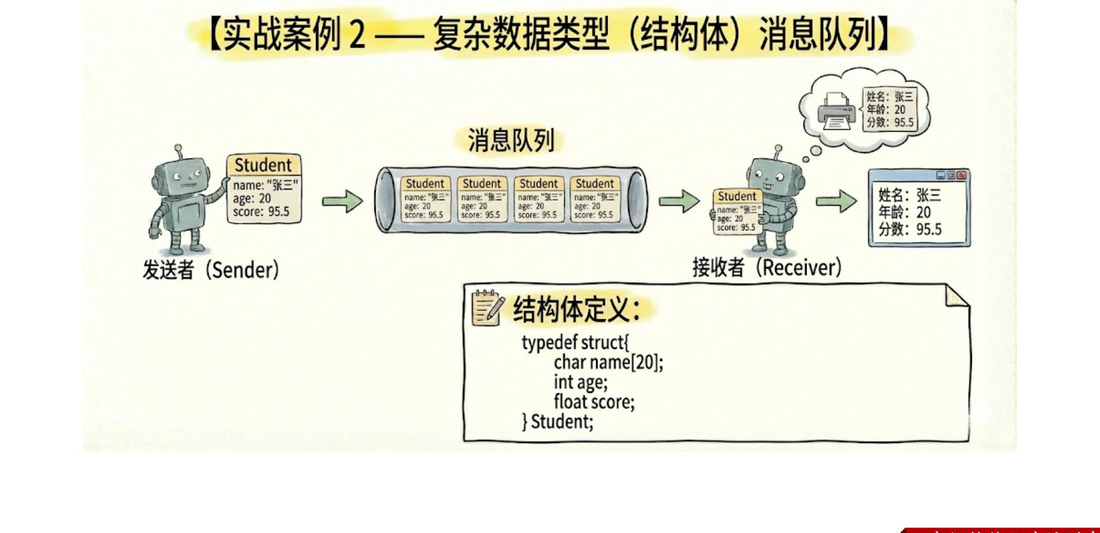

当一条消息包含多个字段时，可以把结构体作为队列元素。课件中的示例结构体为：

```c
typedef struct {
    char name[20];
    int age;
    float score;
} Student;
```

创建、发送和接收时都使用同一种元素大小：

```c
QueueHandle_t studentQueue = xQueueCreate(4, sizeof(Student));
if (studentQueue == NULL) {
    handle_queue_create_error();
    return;
}

Student sender = {"张三", 20, 95.5f};
if (xQueueSend(studentQueue, &sender, 0) != pdPASS) {
    handle_send_error();
    return;
}

Student receiver;
if (xQueueReceive(studentQueue, &receiver, portMAX_DELAY) == pdPASS) {
    printf("姓名=%s 年龄=%d 分数=%.1f\n",
           receiver.name, receiver.age, receiver.score);
}
```

队列复制的是整个结构体的字节内容。结构体内如果包含指针，队列只会复制指针数值，不会自动复制指针指向的动态内存；这类设计需要额外管理对象生命周期。

字符串也可以作为固定长度字符数组传递，但必须约定最大长度，并保证发送与接收缓冲区布局一致。

例如队列元素为 `char[20]` 时，可用 `char text[20] = "hello";` 发送 `text`，并接收到另一块20字节数组中。不要把更短的字符串字面量作为固定20字节复制的源对象；文本还应保留结尾的 `\0`。结构体大小受编译器对齐规则影响，`name[20]` 只是一个字段的长度，不能当作整个 `Student` 的大小。


## 10. 数据类型、缓冲区与中断边界

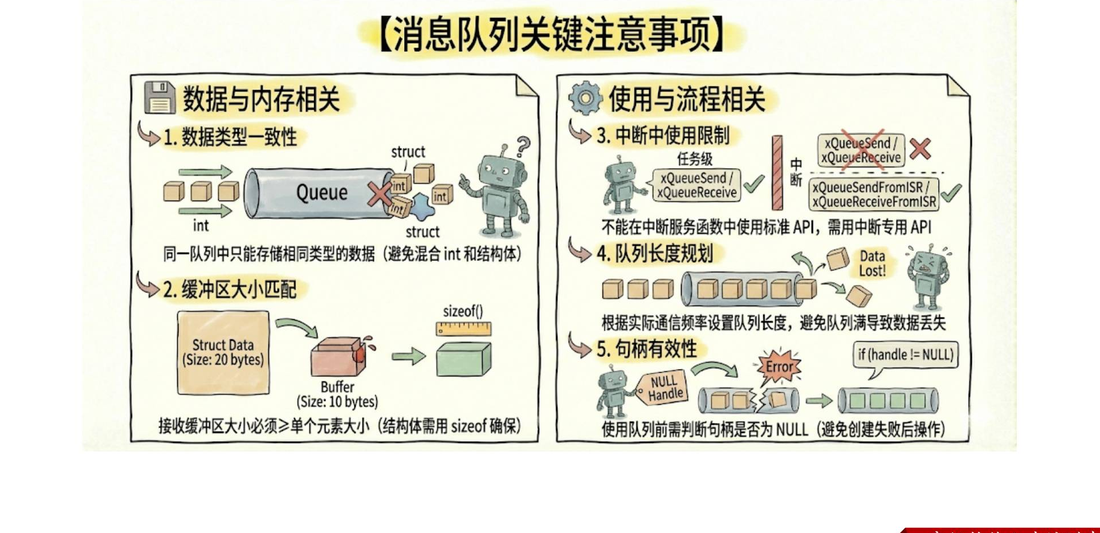

### 队列元素类型必须一致

同一个队列应按约定的元素大小和数据布局使用。用 `sizeof(int)` 创建的队列却发送 `Student`，内核只复制前 `sizeof(int)` 字节，接收方无法得到完整结构体。反过来，用结构体队列发送一个小 `int`，内核会越界读取源对象；接收缓冲区过小还会导致越界写入。

### 接收缓冲区要足够大

接收结构体时，缓冲区至少要有 `sizeof(Student)` 字节。数组和结构体优先使用 `sizeof`，避免手写长度与实际定义不一致。

### 区分任务 API 和 ISR API

任务中使用 `xQueueSend()`、`xQueueReceive()`；中断中使用 `xQueueSendFromISR()`、`xQueueReceiveFromISR()`。ISR 版本不能等待任意时长，应保持中断服务简短，把复杂处理交给任务。

### 规划队列长度

根据消息产生频率、接收任务处理时间和允许的峰值积压量设置长度。发送失败时要有明确策略：丢弃、覆盖旧消息、记录错误，或者让发送方短暂等待。

普通 `xQueueSend()` 不会自动覆盖旧消息。需要只保留最新状态时，可选长度为1的队列并使用 `xQueueOverwrite()`，这是工程补充方案，不属于本课件核心 API。

### 检查句柄和返回值

创建后检查句柄是否为 `NULL`，发送和接收后检查返回值。不要在队列创建失败后继续调用 API。


## 11. 设计检查与调试建议

把消息队列接入工程时，可以沿着数据流逐项检查：

1. 明确消息的所有字段、单位和有效范围，先定义好结构体或固定长度数组。
2. 计算单个元素大小和队列容量，估算 RAM 使用量与最坏积压数量。
3. 给发送端和接收端记录计数，区分“没有消息”“队列已满”和“处理失败”。
4. 对超时、丢弃和异常数据设计可观察的日志或状态码。
5. 如果队列传递的是指针，明确谁分配、谁释放，以及接收任务何时结束使用。

容量估算时，队列的数据存储约为“元素数量 × 单个元素大小”，还需计入队列控制块和分配开销。若生产速度长期高于消费速度，增加长度只能推迟队列满，仍需降低发送频率、提高处理速度或明确丢弃策略。

可设计三组验证：发送500、2000后按相同顺序接收；填满队列后验证零等待发送返回失败；让队列为空后验证接收超时。结构体则对比发送前与接收后的各字段。这些是待执行的验证方法。

这些步骤帮助定位通信问题，但不代表已经执行了某个具体芯片工程的编译或板级测试。


## 12. 核心总结

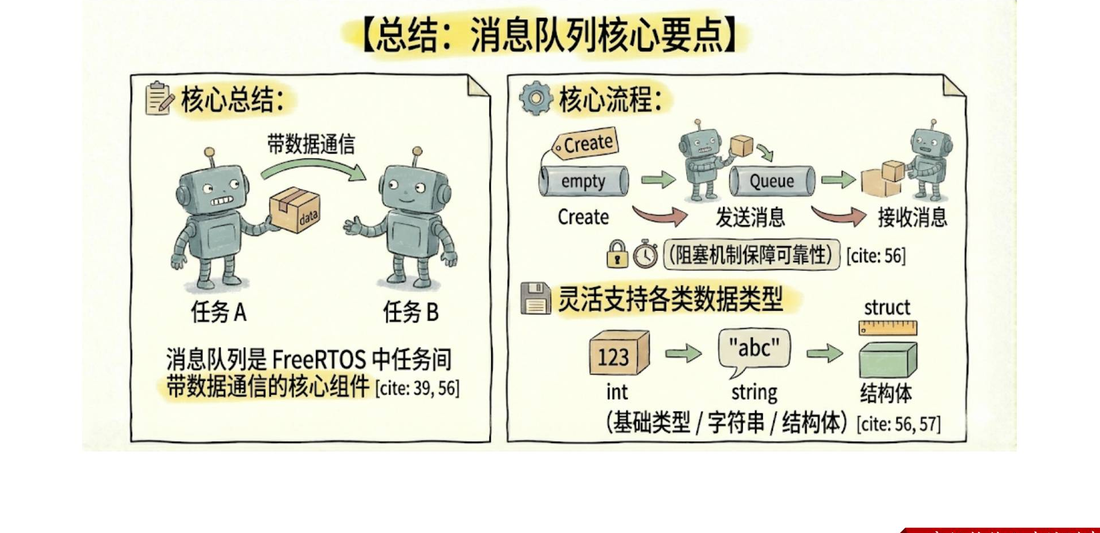

- **作用**：消息队列是 FreeRTOS 中带数据的任务间通信组件，支持按 FIFO 顺序传递消息。
- **创建**：`xQueueCreate(uxQueueLength, uxItemSize)` 预先确定队列长度和单个元素大小，失败时返回 `NULL`。
- **发送**：`xQueueSend()` 把一个元素复制进队列，队列满时可以等待或立即失败。
- **接收**：`xQueueReceive()` 从队列头部复制一个元素，队列空时可以阻塞等待。
- **数据类型**：`int`、定长字符串和结构体都可以传递，但发送端、接收端和队列定义必须保持一致。
- **边界**：任务与 ISR 使用不同 API；队列长度、缓冲区大小和返回值都需要显式规划与检查。

消息队列适合把“产生数据”和“处理数据”拆成不同任务，是构建传感器采集、按键控制和设备命令通道的基础组件。

本篇依据课程 PPT 整理，未进行开发板编译、下载或运行验证。
